<a href="https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_3_3_Optimization_Gradient_Descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ehuangasu/MAT422/blob/main/MAT422_Section_3_3_Optimization_Gradient_Descent.ipynb)

# MAT 422 - Section 3.3: Optimization and Gradient Descent

**Topics:** Necessary and sufficient conditions of local minimizers, Convexity and global minimizers, Gradient descent

> Student note: This Colab badge is required for submission. Create or edit the notebook in Google Colab, then save it directly to GitHub so the badge/icon remains available for grading and reruns.


In [17]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)


## Necessary and sufficient conditions of local minimizers

This section gives one compact Python demonstration of **Necessary and sufficient conditions of local minimizers**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.

Two conditions:
f'(x) = 0
f''(x) >= 0
Each of them on their own is necessary.
What is sufficent is **both** of the below:
f'(x) = 0
f''(x) > 0

Note the second derivative is > instead of >=.

x=-1: f'(x)=0, f''(x)=8, f(x)=0
x=0: f'(x)=0, f''(x)=-4, f(x)=1
x=1: f'(x)=0, f''(x)=8, f(x)=0


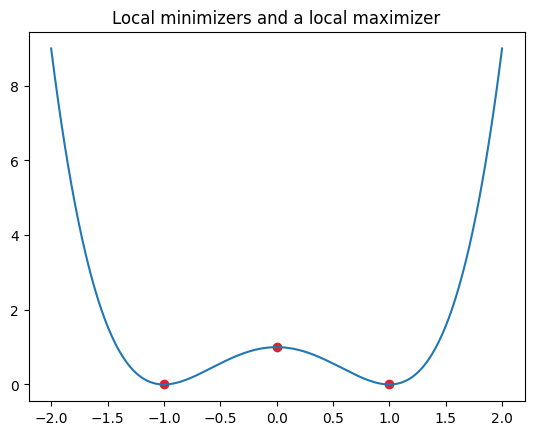

In [18]:
def f(x):
    return (x**2 - 1)**2

def fp(x):
    return 4*x*(x**2 - 1)

def fpp(x):
    return 12*x**2 - 4

critical_points = np.array([-1, 0, 1])
for c in critical_points:
    print(f"x={c}: f'(x)={fp(c)}, f''(x)={fpp(c)}, f(x)={f(c)}")

x = np.linspace(-2, 2, 400)
plt.plot(x, f(x))
plt.scatter(critical_points, f(critical_points), color="tab:red")
plt.title("Local minimizers and a local maximizer")
plt.show()


x^4: f'(0) = 0.0, f''(0) = 0.0
x^3: f'(0) = 0.0, f''(0) = 0.0


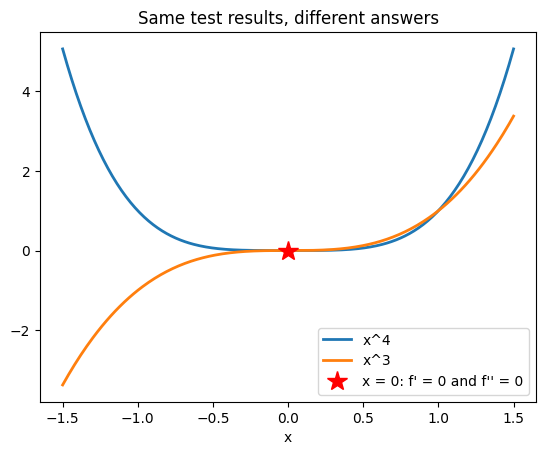

In [19]:
xs = np.linspace(-1.5, 1.5, 300)
for p in [4, 3]:
    print(f"x^{p}: f'(0) = {p * 0.0**(p-1)}, f''(0) = {p * (p-1) * 0.0**(p-2)}")
    plt.plot(xs, xs**p, lw=2, label=f"x^{p}")
plt.plot(0, 0, "r*", ms=15, label="x = 0: f' = 0 and f'' = 0")
plt.title("Same test results, different answers")
plt.xlabel("x")
plt.legend()
plt.show()

In the necessary/sufficent cases described, there is an edge case:
f'(x) = 0
f''(x) = 0

it satisfies necessary but is not sufficient. In the two functions shown, both are true, but one is a local minimum but one is not.

## Convexity and global minimizers

This section gives one compact Python demonstration of **Convexity and global minimizers**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.

A function is convex if the chord between any two points on the graph doesn't go below the graph. In a convex function, every local min is a global min, because if not the line connecting the two goes under the function (there is a x' value right next to the local min x in the direction of the global min x_global, f(x')>f(x), line(x') < f(x))

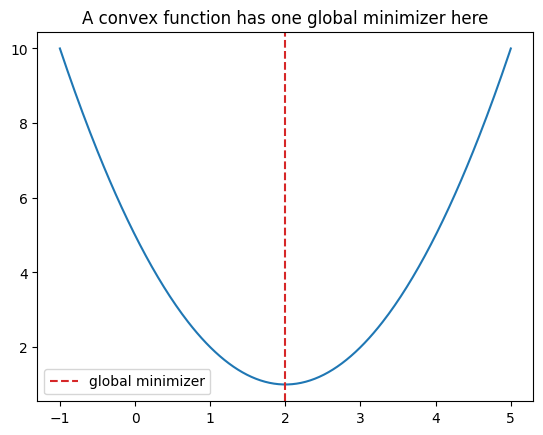

In [20]:
def g(x):
    return (x - 2)**2 + 1

x = np.linspace(-1, 5, 300)
plt.plot(x, g(x))
plt.axvline(2, color="tab:red", linestyle="--", label="global minimizer")
plt.title("A convex function has one global minimizer here")
plt.legend()
plt.show()


local minimizers of h: [-1.30084  1.1309 ]  values h(x): [-3.51391 -1.07023]


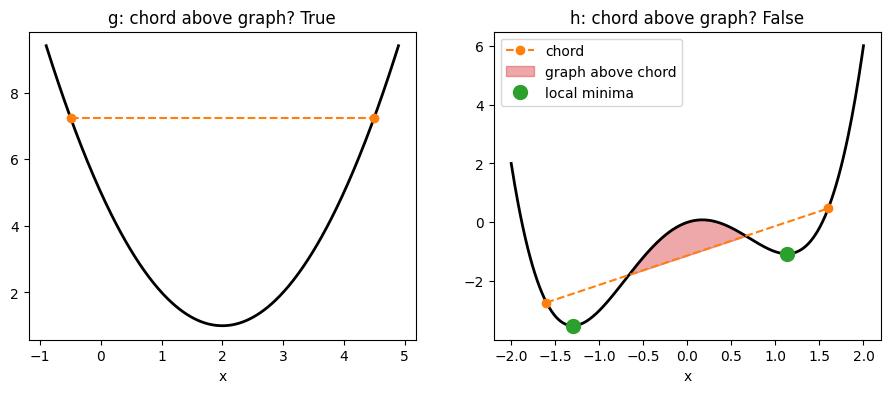

In [21]:
def h(x):
    return x**4 - 3*x**2 + x

t = np.linspace(0, 1, 100)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, func, p, q in [(ax[0], g, -0.5, 4.5), (ax[1], h, -1.6, 1.6)]:
    xs = np.linspace(p - 0.4, q + 0.4, 300)
    seg = (1 - t) * p + t * q
    chord, curve = (1 - t) * func(p) + t * func(q), func(seg)
    a.plot(xs, func(xs), "k", lw=2)
    a.plot([p, q], [func(p), func(q)], "C1o--", label="chord")
    a.fill_between(seg, chord, curve, where=curve > chord, color="C3", alpha=0.4, label="graph above chord")
    a.set(title=f"{func.__name__}: chord above graph? {np.all(chord >= curve)}", xlabel="x")

crit = np.sort(np.roots([4, 0, -6, 1]).real)
mins = crit[12*crit**2 - 6 > 0]
print("local minimizers of h:", mins, " values h(x):", h(mins))
ax[1].plot(mins, h(mins), "C2o", ms=10, label="local minima")
ax[1].legend()
plt.show()

For the parabola, any chord is above the graph so it is convex, so we are sure the local minimum spotted is the global minum. For the quartic, there is a chord that goes under the graph, so it is not convex. We see that there is a global and local min. Note that nonconvexity does not imply a local minimum.

## Gradient descent

This section gives one compact Python demonstration of **Gradient descent**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


Final x = 1.9998903152467982
Final objective = 1.000000012030745


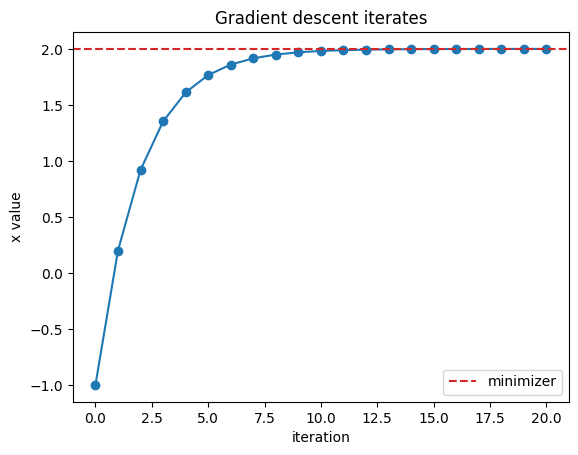

In [22]:
def grad_g(x):
    return 2 * (x - 2)

learning_rate = 0.2
current = -1.0
path = [current]
for _ in range(20):
    current = current - learning_rate * grad_g(current)
    path.append(current)

path = np.array(path)
print("Final x =", path[-1])
print("Final objective =", g(path[-1]))

plt.plot(path, marker="o")
plt.axhline(2, color="tab:red", linestyle="--", label="minimizer")
plt.xlabel("iteration")
plt.ylabel("x value")
plt.title("Gradient descent iterates")
plt.legend()
plt.show()


g, lr = 0.2: x after 8 steps = 1.94961
g, lr = 0.45: x after 8 steps = 2.00000
g, lr = 1.05: x after 8 steps = -4.43077
h, start -0.5: ends at x = -1.3008, h = -3.5139
h, start 0.5: ends at x = 1.1309, h = -1.0702


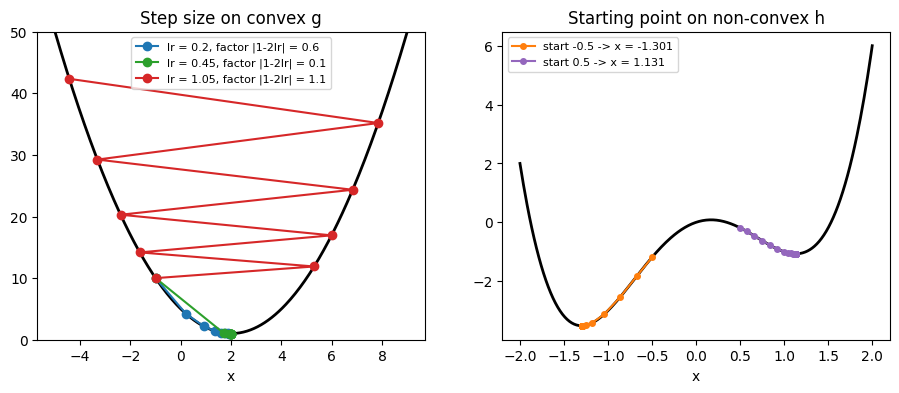

In [23]:
def gradient_descent(grad, x0, lr, steps):
    xs = [x0]
    for _ in range(steps):
        xs.append(xs[-1] - lr * grad(xs[-1]))
    return np.array(xs)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
xs = np.linspace(-5, 9, 300)
ax[0].plot(xs, g(xs), "k", lw=2)
for lr, color in [(0.2, "C0"), (0.45, "C2"), (1.05, "C3")]:
    run = gradient_descent(grad_g, -1.0, lr, steps=8)
    print(f"g, lr = {lr}: x after 8 steps = {run[-1]:.5f}")
    ax[0].plot(run, g(run), "o-", color=color, label=f"lr = {lr}, factor |1-2lr| = {abs(1 - 2*lr):.1f}")
ax[0].set(title="Step size on convex g", xlabel="x", ylim=(0, 50))
ax[0].legend(fontsize=8)

xs = np.linspace(-2, 2, 300)
ax[1].plot(xs, h(xs), "k", lw=2)
for x0, color in [(-0.5, "C1"), (0.5, "C4")]:
    run = gradient_descent(lambda x: 4*x**3 - 6*x + 1, x0, lr=0.05, steps=25)
    print(f"h, start {x0}: ends at x = {run[-1]:.4f}, h = {h(run[-1]):.4f}")
    ax[1].plot(run, h(run), "o-", color=color, ms=4, label=f"start {x0} -> x = {run[-1]:.3f}")
ax[1].set(title="Starting point on non-convex h", xlabel="x")
ax[1].legend(fontsize=8)
plt.show()

We see at lr=0.2, it converges to the global minimum. With lr=0.45 it converges faster. However, higher lr does not necessarily mean faster convergence, as with lr=1.05 gradient descent overshoots and starts climbing outwards. In the graph to the right, we see two gradient descents starting from different points going towards a global and local min, so it can get "stuck" on a local minimum.

## Reflection and Submission Checklist

- I explained each concept in words before or after the code.
- I verified important claims numerically or visually.
- I changed or extended at least one example so the notebook reflects my own work.
- I ran the notebook from top to bottom without errors.
- I saved the notebook from Google Colab directly to GitHub, following the course instructions.
